<a href="https://colab.research.google.com/github/mysteryea7107/Mapping-Philippine-Grad-School-Talk-PCA-Regression-Big-Four-Reply-Dynamics/blob/main/Notebooks/Mapping_Philippine_Grad_School_Talk_PCA%2C_Regression_%26_Big_Four_Reply_Dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [56]:
# Google Colab Drive Connection
from google.colab import drive

# Text Vectorization, Scaling & PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [57]:
drive.mount('/content/drive')

posts_path = '/content/drive/MyDrive/Data Project/PCA_Reddit/JSON/r_gradschoolph_posts.jsonl'
comments_path = '/content/drive/MyDrive/Data Project/PCA_Reddit/JSON/r_gradschoolph_comments.jsonl'

df_posts = pd.read_json(posts_path, lines=True)
df_comments = pd.read_json(comments_path, lines=True)

print(f"Posts Dataset Shape:    {df_posts.shape[0]} rows, {df_posts.shape[1]} columns")
print(f"Comments Dataset Shape: {df_comments.shape[0]} rows, {df_comments.shape[1]} columns")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Posts Dataset Shape:    5413 rows, 127 columns
Comments Dataset Shape: 31291 rows, 85 columns


In [58]:
# 1. Inspect Date Range & Raw Counts
df_posts['created_dt'] = pd.to_datetime(df_posts['created_utc'], unit='s')
df_comments['created_dt'] = pd.to_datetime(df_comments['created_utc'], unit='s')

print(f"Date Range: {df_posts['created_dt'].min().date()} to {df_posts['created_dt'].max().date()}")
print(f"Raw Posts: {len(df_posts):,} | Raw Comments: {len(df_comments):,}")

Date Range: 2022-08-27 to 2026-11-21
Raw Posts: 5,413 | Raw Comments: 31,291


In [60]:
# A. Define University Tiers (Top PH Univ vs. Other PH Univ)
# ---------------------------------------------------------
top_ph_univ_patterns = {
    "UP System": r"\b(up|upd|upm|uplb|upv|upb|upc|upmin|upou|updepp|diliman|los banos|elbi|peyups|iskolar|iska|isko)\b",
    "Ateneo": r"\b(ateneo|admu|addu|adzu|adnu|katipunan|loyola)\b",
    "De La Salle": r"\b(dlsu|lasalle|la salle|taft|benilde|csb)\b",
    "UST": r"\b(ust|santo tomas|thomasian|espana)\b",
}

other_ph_univ_patterns = {
    "PUP": r"\b(pup|pupian|sta mesa)\b",
    "Mapua": r"\b(mapua|mit)\b",
    "FEU": r"\b(feu|far eastern|tamaraw)\b",
    "UE": r"\b(ue|university of the east)\b",
    "NU": r"\b(nu|national u|national university)\b",
    "AdU": r"\b(adu|adamson)\b",
    "AIM": r"\b(aim|asian institute of management)\b",
    "UA&P": r"\b(uap|asia and the pacific)\b",
    "PLM": r"\b(plm|pamantasan)\b",
    "TUP": r"\b(tup)\b",
    "TIP": r"\b(tip|technological institute of the philippines)\b",
    "USC": r"\b(usc|san carlos)\b",
    "MSU-IIT": r"\b(msu|iit|msuiit)\b",
    "SLU": r"\b(slu|saint louis)\b",
    "Silliman": r"\b(silliman|siliman)\b",
    "Other PH Univ": r"\b(feu|ceu|lpu|san beda|sbu|arellano|letran|olfu|fatima|neu|mapua|dlsu|ust|admu|uplb|upd|upm|bulsu|bsu|batstateu|clsu|slu|usc|msu|plm|tup|tip|rtu|pnu|umak|qcu|plv)\b",
}

In [62]:
# Combine post + comments raw text for university detection
raw_search_text = (
    df_ml["full_text"].fillna("") + " " + df_ml["combined_comments"].fillna("")
).str.lower()

top_regex = "|".join(top_ph_univ_patterns.values())
other_regex = "|".join(other_ph_univ_patterns.values())

has_top = raw_search_text.str.contains(top_regex, regex=True)
has_other = raw_search_text.str.contains(other_regex, regex=True)


def classify_univ_tier(row_top, row_other):
  if row_top and row_other:
    return "Both (Top + Other PH Univ)"
  elif row_top:
    return "PH Top Univ"
  elif row_other:
    return "Other PH Univ"
  else:
    return "No Specific Univ Mentioned"


df_ml["univ_tier"] = [
    classify_univ_tier(t, o) for t, o in zip(has_top, has_other)
]
df_ml["is_top_ph_univ"] = has_top.astype(int)
df_ml["is_other_ph_univ"] = (has_other & ~has_top).astype(int)

print("=== UNIVERSITY TIER BREAKDOWN ===")
print(df_ml["univ_tier"].value_counts(dropna=False))

/tmp/ipykernel_2673/1827101296.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_top = raw_search_text.str.contains(top_regex, regex=True)
/tmp/ipykernel_2673/1827101296.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_other = raw_search_text.str.contains(other_regex, regex=True)


=== UNIVERSITY TIER BREAKDOWN ===
univ_tier
Both (Top + Other PH Univ)    1987
No Specific Univ Mentioned    1536
PH Top Univ                    764
Other PH Univ                  539
Name: count, dtype: int64


In [64]:
# B. Clean Text WITHOUT Dropping University Names
# ---------------------------------------------------------
# Keep university terms so PCA captures institutional differences
ph_univ_keep_or_light_stop = {
    "univ",
    "university",
    "school",
    "college",
    "campus",
    "grad",
    "graduate",
    "gradschool",
    "ph",
    "philippines",
}

taglish_stopwords = {
    "po",
    "naman",
    "lang",
    "kasi",
    "yung",
    "ung",
    "mga",
    "sa",
    "na",
    "ng",
    "ang",
    "ko",
    "mo",
    "ako",
    "ka",
    "kami",
    "kayo",
    "sila",
    "niya",
    "nila",
    "namin",
    "natin",
    "din",
    "rin",
    "daw",
    "raw",
    "ba",
    "eh",
    "ah",
    "oh",
    "ha",
    "pa",
    "may",
    "meron",
    "wala",
    "walang",
    "para",
    "kung",
    "pero",
    "kaya",
    "dahil",
    "kapag",
    "pag",
    "habang",
    "talaga",
    "sobra",
    "medyo",
    "parang",
    "actually",
    "basically",
    "just",
    "like",
    "really",
    "know",
    "want",
    "need",
    "help",
    "please",
    "pls",
    "guys",
    "anyone",
    "ask",
    "question",
    "questions",
    "hi",
    "hello",
    "thanks",
    "thank",
    "advance",
    "tia",
    "amp",
    "https",
    "www",
    "com",
}

all_stopwords_clean = taglish_stopwords.union(ph_univ_keep_or_light_stop)

In [66]:
def clean_reddit_text_with_univ(text):
  text = str(text).lower()
  text = re.sub(r"http\S+|www\.\S+", "", text)
  text = re.sub(r"&amp;|&lt;|&gt;|&#x200B;", " ", text)
  text = re.sub(r"[^a-z0-9\s]", " ", text)
  tokens = [w for w in text.split() if len(w) > 1 and w not in all_stopwords_clean]
  return " ".join(tokens)

In [67]:
df_ml["thread_text_univ"] = (
    df_ml["full_text"] + " " + df_ml["combined_comments"].fillna("")
).apply(clean_reddit_text_with_univ)

# ---------------------------------------------------------
# C. TF-IDF + Standardization + PCA
# ---------------------------------------------------------
tfidf = TfidfVectorizer(
    max_features=500, stop_words="english", ngram_range=(1, 2), min_df=5
)
X_tfidf = tfidf.fit_transform(df_ml["thread_text_univ"]).toarray()
feature_names = tfidf.get_feature_names_out()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_tfidf)

pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)

for i in range(5):
  df_ml[f"PC{i+1}"] = X_pca[:, i]

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(10)],
    index=feature_names,
)

In [69]:
print("\n=== PCA TOP LOADINGS (PC1 - PC5) ===")
for i in range(5):
  col = f"PC{i+1}"
  var_pct = pca.explained_variance_ratio_[i] * 100
  pos = loadings[col].nlargest(6).index.tolist()
  neg = loadings[col].nsmallest(6).index.tolist()
  print(f"{col} ({var_pct:.2f}%): (+) {', '.join(pos)} | (-) {', '.join(neg)}")

print("\n=== MEAN PC1-PC3 BY UNIVERSITY TIER ===")
print(
    df_ml.groupby("univ_tier")[
        ["PC1", "PC2", "PC3", "valid_reply_count", "has_reply"]
    ].agg(
        count=("has_reply", "count"),
        reply_rate=("has_reply", "mean"),
        median_replies=("valid_reply_count", "median"),
        PC1_mean=("PC1", "mean"),
        PC2_mean=("PC2", "mean"),
        PC3_mean=("PC3", "mean"),
    )
)


=== PCA TOP LOADINGS (PC1 - PC5) ===
PC1 (1.68%): (+) work, hindi, time, di, mas, don | (-) planning enroll, manila, received, survey, entrance exam, planning
PC2 (1.16%): (+) email, nag, di, results, received, enrollment | (-) career, degree, currently, master, industry, skills
PC3 (0.96%): (+) received, got, results, email, did, luck | (-) gusto, mag, hindi, dito, di, non thesis
PC4 (0.81%): (+) clinical, psych, clinical psych, ma, ma clinical, psychology | (-) mba, data, business, aim, management, science
PC5 (0.79%): (+) classes, online, class, f2f, hybrid, weekdays | (-) clinical, psych, research, field, clinical psych, psychology

=== MEAN PC1-PC3 BY UNIVERSITY TIER ===
                            count  reply_rate  median_replies  PC1_mean  \
univ_tier                                                                 
Both (Top + Other PH Univ)   1987    0.869149             4.0  0.560644   
No Specific Univ Mentioned   1536    0.589844             1.0 -0.680078   
Other PH Univ 

In [72]:
import statsmodels.api as sm

# ----------------------------------------------------------
# D. Linear Regression: Predicting Log Reply Volume & PC1
# ---------------------------------------------------------
df_ml["has_question_mark"] = df_ml["title"].str.contains(r"\?", regex=True).astype(int)
df_ml["log_word_count"] = np.log1p(df_ml["full_text"].str.split().str.len())
df_ml["log_replies"] = np.log1p(df_ml["valid_reply_count"])
df_ml["month_num"] = df_ml["created_dt"].dt.month

# One-hot encode univ_tier (reference: 'No Specific Univ Mentioned')
univ_dummies = pd.get_dummies(
    df_ml["univ_tier"], prefix="univ", drop_first=False, dtype=float
)
ref_col = "univ_No Specific Univ Mentioned"
feature_cols = [c for c in univ_dummies.columns if c != ref_col]

X_reg = pd.concat(
    [
        univ_dummies[feature_cols],
        df_ml[["has_question_mark", "log_word_count", "month_num"]].astype(float),
    ],
    axis=1,
)
X_reg_sm = sm.add_constant(X_reg)

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")

# Individual universities: (Display Name, Regex Pattern, Tier)
univ_catalog = [
    # Big Four
    (
        "UP",
        (
            r"\b(up|upd|upm|uplb|upv|upb|upc|upmin|upou|updepp|diliman|los"
            r" banos|elbi|peyups|iskolar|iska|isko)\b"
        ),
        "Big Four",
    ),
    ("Ateneo", r"\b(ateneo|admu|addu|adzu|adnu|katipunan|loyola)\b", "Big Four"),
    ("DLSU", r"\b(dlsu|lasalle|la salle|taft|benilde|csb)\b", "Big Four"),
    ("UST", r"\b(ust|santo tomas|thomasian|espana)\b", "Big Four"),
    # Not Big Four
    ("PUP", r"\b(pup|pupian|sta mesa)\b", "Not Big Four"),
    ("Mapúa", r"\b(mapua|mit)\b", "Not Big Four"),
    ("FEU", r"\b(feu|far eastern|tamaraw)\b", "Not Big Four"),
    ("UE", r"\b(ue|university of the east)\b", "Not Big Four"),
    ("NU", r"\b(nu|national u|national university)\b", "Not Big Four"),
    ("Adamson", r"\b(adu|adamson)\b", "Not Big Four"),
    ("PLM", r"\b(plm|pamantasan)\b", "Not Big Four"),
    ("TUP", r"\b(tup)\b", "Not Big Four"),
    ("TIP", r"\b(tip|technological institute of the philippines)\b", "Not Big Four"),
    ("AIM", r"\b(aim|asian institute of management)\b", "Not Big Four"),
    ("UA&P", r"\b(uap|asia and the pacific)\b", "Not Big Four"),
    ("USC", r"\b(usc|san carlos)\b", "Not Big Four"),
    ("MSU-IIT", r"\b(msu|iit|msuiit)\b", "Not Big Four"),
    ("SLU", r"\b(slu|saint louis)\b", "Not Big Four"),
    ("Silliman", r"\b(silliman|siliman)\b", "Not Big Four"),
    ("San Beda", r"\b(san beda|sbu)\b", "Not Big Four"),
]

# Search across post + comments text
corpus = (
    df_ml["full_text"].fillna("") + " " + df_ml["combined_comments"].fillna("")
).str.lower()

rows = []
for name, pattern, tier in univ_catalog:
  mask = corpus.str.contains(pattern, regex=True)
  sub = df_ml[mask]
  if len(sub) > 0:
    rows.append({
        "university": name,
        "tier": tier,
        "threads": len(sub),
        "reply_rate_pct": sub["has_reply"].mean() * 100,
        "mean_replies": sub["valid_reply_count"].mean(),
        "median_replies": sub["valid_reply_count"].median(),
        "median_first_reply_hrs": sub["time_to_first_reply_mins"].median() / 60.0,
    })

univ_df = pd.DataFrame(rows)
print(
    univ_df.sort_values(["tier", "threads"], ascending=[True, False]).to_string(
        index=False
    )
)

/tmp/ipykernel_2673/4281814884.py:45: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = corpus.str.contains(pattern, regex=True)


university         tier  threads  reply_rate_pct  mean_replies  median_replies  median_first_reply_hrs
        UP     Big Four     1904       86.764706      7.886555             4.0                0.953333
      DLSU     Big Four     1073       88.630009      8.985089             4.0                0.746667
    Ateneo     Big Four      655       88.854962     10.293130             5.0                0.890833
       UST     Big Four      408       87.254902      9.838235             5.0                0.719306
       PUP Not Big Four      408       83.333333      9.024510             4.0                1.080417
       AIM Not Big Four      299       95.986622     14.177258             8.0                0.605278
     Mapúa Not Big Four      262       87.022901     11.977099             5.0                0.820694
       PLM Not Big Four      119       84.033613     11.991597             4.0                1.187639
       FEU Not Big Four       87       83.908046      9.540230           

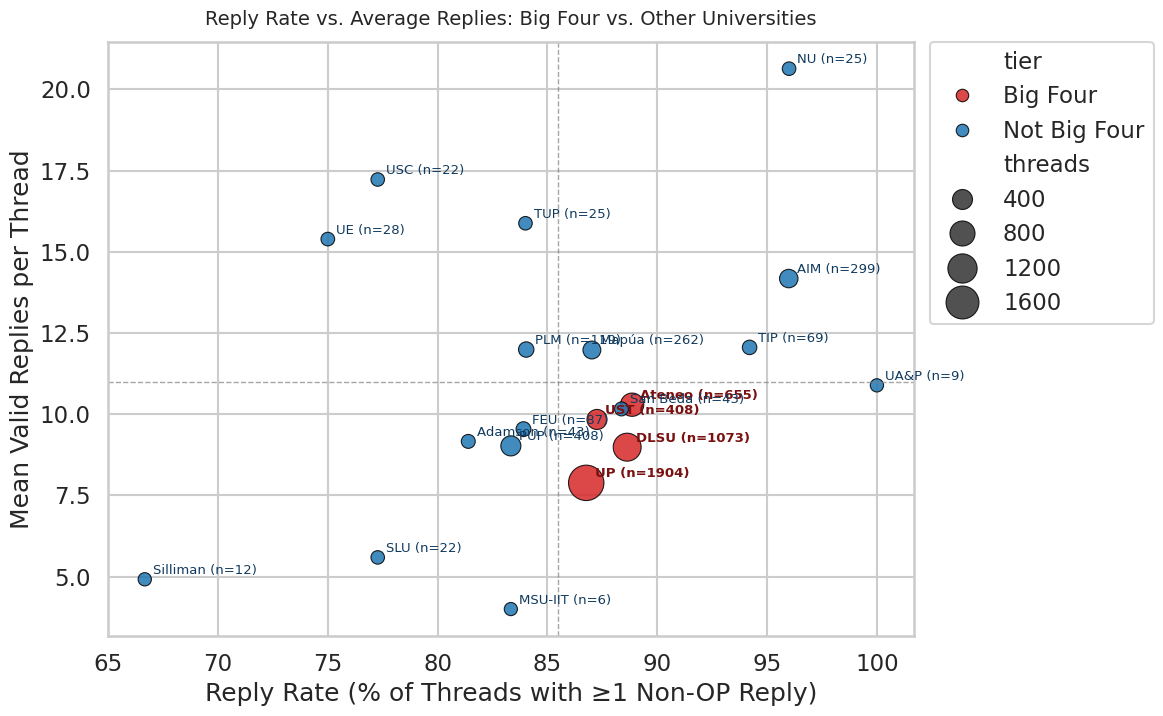

In [81]:
plt.figure(figsize=(12, 7.5))

palette = {
    "Big Four": "#D62728",      # Highlighted Big Four color
    "Not Big Four": "#1F77B4",  # Non-Big Four comparison color
}

ax = sns.scatterplot(
    data=univ_df,
    x="reply_rate_pct",
    y="mean_replies",
    hue="tier",
    size="threads",
    sizes=(90, 650),
    palette=palette,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.8,
)

# Label every individual university name on the scatter plot
for _, r in univ_df.iterrows():
  ax.annotate(
      f"{r['university']} (n={r['threads']})",
      (r["reply_rate_pct"], r["mean_replies"]),
      xytext=(6, 4),
      textcoords="offset points",
      fontsize=9.5,
      fontweight="bold" if r["tier"] == "Big Four" else "normal",
      color="#7A1010" if r["tier"] == "Big Four" else "#103A5E",
  )

# Reference lines for overall averages across listed schools
plt.axvline(
    univ_df["reply_rate_pct"].mean(),
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)
plt.axhline(
    univ_df["mean_replies"].mean(),
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

plt.title(
    "Reply Rate vs. Average Replies: Big Four vs. Other Universities",
    fontsize=14,
    pad=12,
)
plt.xlabel("Reply Rate (% of Threads with ≥1 Non-OP Reply)")
plt.ylabel("Mean Valid Replies per Thread")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()


In [83]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

# 1. Inspect top words per K-Means cluster (using TF-IDF mean scores)
cluster_topic_names = {
    0: "Admissions, Application & Results",
    1: "Work-Study & Balancing Job + Grad School",
    2: "Thesis vs. Non-Thesis & Research Track",
    3: "Classes, Schedule, Online vs. Hybrid/F2F",
    4: "Program Selection, Career & ROI",
    5: "Tuition, Scholarships & Financial Aid",
    6: "Clinical Psych, Boards & Specialization",
    7: "Surveys, Data & Academic Requirements",
}

df_ml["grad_topic"] = df_ml["Cluster"].map(cluster_topic_names).fillna("General Grad School")

topic_summary = (
    df_ml.groupby("grad_topic")
    .agg(
        threads=("id", "count"),
        share_pct=("id", lambda s: len(s) / len(df_ml) * 100),
        question_rate_pct=("has_question_mark", lambda s: s.mean() * 100),
        reply_rate_pct=("has_reply", lambda s: s.mean() * 100),
        median_replies=("valid_reply_count", "median"),
    )
    .sort_values("threads", ascending=False)
)

print("=== TOP GRAD SCHOOL TOPICS (CLUSTER / PCA SUMMARY) ===")
print(topic_summary.round(2).to_string())

=== TOP GRAD SCHOOL TOPICS (CLUSTER / PCA SUMMARY) ===
                                          threads  share_pct  question_rate_pct  reply_rate_pct  median_replies
grad_topic                                                                                                     
Program Selection, Career & ROI              1526      31.62              21.23           56.49             1.0
Surveys, Data & Academic Requirements         628      13.01              43.63           94.27             4.0
Clinical Psych, Boards & Specialization       510      10.57              35.29           97.06             7.0
Classes, Schedule, Online vs. Hybrid/F2F      500      10.36              19.20           87.60             3.0
Thesis vs. Non-Thesis & Research Track        489      10.13              13.29           81.80             3.0
Work-Study & Balancing Job + Grad School      459       9.51              18.30           55.12             1.0
Tuition, Scholarships & Financial Aid         441

In [85]:
question_patterns = {
    "Work-Study Balance (Job + Grad School)": (
        r"\b(working|work|full.?time|night shift|schedule|time management|load|units|pagod)\b"
    ),
    "Thesis vs. Non-Thesis / Capstone": (
        r"\b(thesis|non.?thesis|capstone|comprehensive exam|defense|proposal|rrl)\b"
    ),
    "Admissions, Requirements & Deadlines": (
        r"\b(admission|admissions|application|apply|interview|tor|recommendation|deadline|results|exam|qualifying)\b"
    ),
    "Tuition, Fees & Scholarships": (
        r"\b(tuition|fee|fees|scholarship|stipend|dost|che|installment|magkano|cost|budget)\b"
    ),
    "Class Modality (Online, Hybrid, F2F, Weekends)": (
        r"\b(online|hybrid|f2f|face to face|weekend|weekends|saturday|sunday|evening|class)\b"
    ),
    "ROI, Career Shift & Worth It": (
        r"\b(worth it|roi|career|promotion|salary|shift|transition|industry|advantage)\b"
    ),
    "School & Program Comparison": (
        r"\b(vs|versus|compare|comparison|recommend|recommendation|which school|which univ|better)\b"
    ),
}

question_mask = (
    df_ml["title"].fillna("").str.contains(r"\?", regex=True)
    | df_ml["full_text"]
    .fillna("")
    .str.lower()
    .str.contains(
        r"\b(how|what|which|when|where|why|worth it|any tips|anyone|paano|ano|magkano|pwede)\b",
        regex=True,
    )
)

q_df = df_ml[question_mask].copy()
text_q = (q_df["title"].fillna("") + " " + q_df["selftext"].fillna("")).str.lower()

q_rows = []
for label, pat in question_patterns.items():
  matched = text_q.str.contains(pat, regex=True)
  sub = q_df[matched]
  q_rows.append({
      "question_theme": label,
      "question_threads": len(sub),
      "pct_of_questions": len(sub) / max(len(q_df), 1) * 100,
      "reply_rate_pct": sub["has_reply"].mean() * 100 if len(sub) > 0 else np.nan,
      "median_replies": sub["valid_reply_count"].median() if len(sub) > 0 else np.nan,
  })

q_summary_df = pd.DataFrame(q_rows).sort_values("question_threads", ascending=False)
print(f"\nTotal Question-Style Threads Detected: {len(q_df):,}")
print(q_summary_df.round(2).to_string(index=False))

/tmp/ipykernel_2673/2682035031.py:30: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
/tmp/ipykernel_2673/2682035031.py:41: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matched = text_q.str.contains(pat, regex=True)



Total Question-Style Threads Detected: 3,307
                                question_theme  question_threads  pct_of_questions  reply_rate_pct  median_replies
        Work-Study Balance (Job + Grad School)              1022             30.90           82.09             3.0
          Admissions, Requirements & Deadlines               929             28.09           77.61             2.0
Class Modality (Online, Hybrid, F2F, Weekends)               634             19.17           76.03             2.0
                  ROI, Career Shift & Worth It               519             15.69           82.08             3.0
                  Tuition, Fees & Scholarships               513             15.51           77.58             2.0
                   School & Program Comparison               452             13.67           85.40             3.0
              Thesis vs. Non-Thesis / Capstone               437             13.21           79.41             3.0


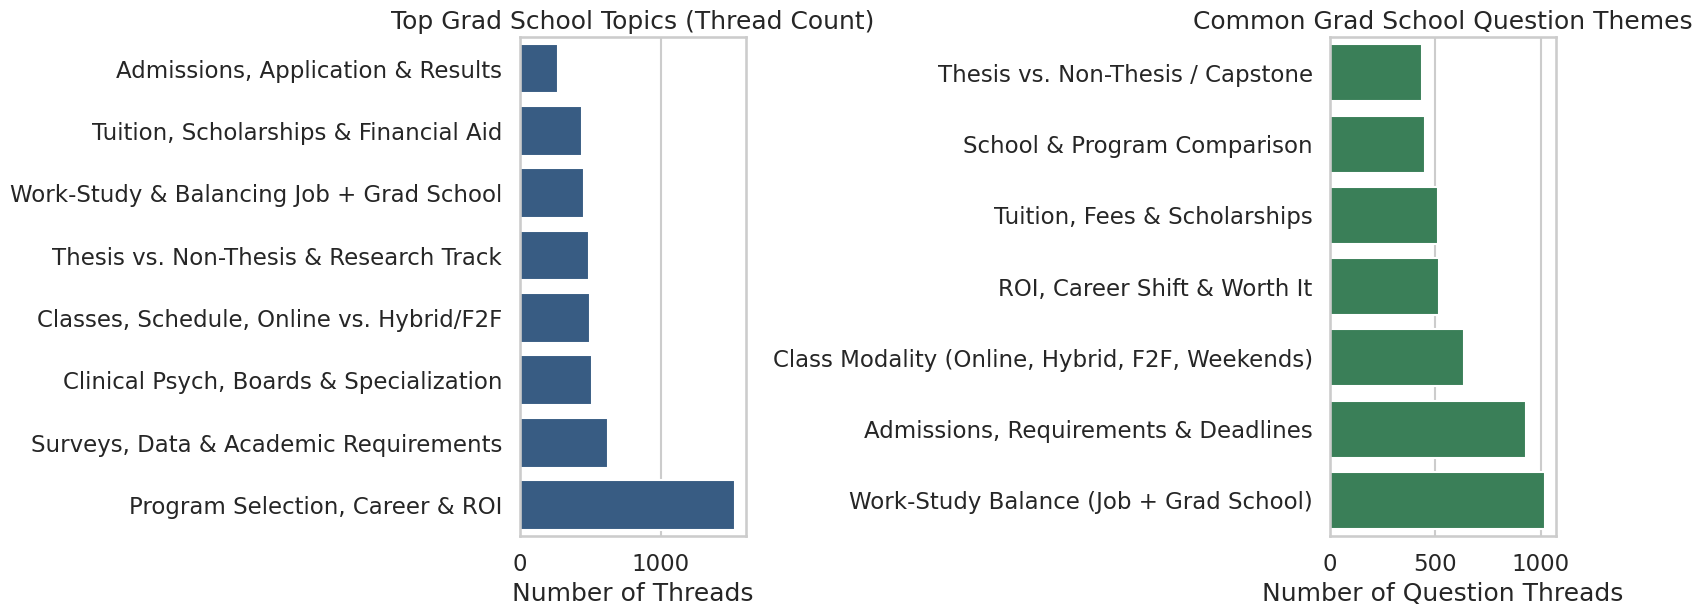

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Left: Top Grad School Topics by Thread Volume
top_topics = topic_summary.reset_index().sort_values("threads", ascending=True)
sns.barplot(
    data=top_topics,
    x="threads",
    y="grad_topic",
    color="#2B5C8F",
    ax=axes[0],
)
axes[0].set_title("Top Grad School Topics (Thread Count)")
axes[0].set_xlabel("Number of Threads")
axes[0].set_ylabel("")

# Right: Common Question Themes (Count & Reply Rate)
q_plot_df = q_summary_df.sort_values("question_threads", ascending=True)
sns.barplot(
    data=q_plot_df,
    x="question_threads",
    y="question_theme",
    color="#2E8B57",
    ax=axes[1],
)
axes[1].set_title("Common Grad School Question Themes")
axes[1].set_xlabel("Number of Question Threads")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [89]:
for label, pat in question_patterns.items():
  matched = text_q.str.contains(pat, regex=True)
  samples = q_df.loc[matched, "title"].dropna().head(3).tolist()
  print(f"\n--- {label} ---")
  for s in samples:
    print(f"  • {s}")

/tmp/ipykernel_2673/332229452.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matched = text_q.str.contains(pat, regex=True)



--- Work-Study Balance (Job + Grad School) ---
  • What made you decide to pursue graduate studies?
  • DLSU Master of Marketing Communications
  • Help me with my thesis by lending me refrigerator space

--- Thesis vs. Non-Thesis / Capstone ---
  • What's next after grad school?
  • Help me with my thesis by lending me refrigerator space
  • MIT Major in SoftDev

--- Admissions, Requirements & Deadlines ---
  • Which comes first: Application Requirements or Recommendation Forms?
  • MIT Major in SoftDev
  • I applied on impulse and got in!

--- Tuition, Fees & Scholarships ---
  • Help me with my thesis by lending me refrigerator space
  • GRADUATE SCHOOL
  • MIT Major in SoftDev

--- Class Modality (Online, Hybrid, F2F, Weekends) ---
  • Must/good read comp sci paper for upcoming grad school student?
  • Master's degree students, where do you live?
  • GRADUATE SCHOOL

--- ROI, Career Shift & Worth It ---
  • What made you decide to pursue graduate studies?
  • Any Suggestions/ Opin

In [92]:
sns.set_theme(style="whitegrid", context="talk")

# Common Philippine graduate programs / disciplines ("courses" in PH usage)
grad_program_patterns = {
    "MBA (Business Administration)": (
        r"\b(mba|master in business administration|master of business"
        r" administration|emba|imba)\b"
    ),
    "Psychology (MA / MS / Clinical / IO / Counseling)": (
        r"\b(psych|psychology|clinical psych|industrial psych|counseling"
        r" psych|developmental psych|ma psych|ms psych)\b"
    ),
    "Education (MAEd / MEd / PhD Ed / Teaching)": (
        r"\b(maed|med|education|educational management|educational"
        r" leadership|teaching|teacher certificate|guidance)\b"
    ),
    "Data Science & Analytics (MSDS / MAIDA / GDDS)": (
        r"\b(data science|msds|maida|gdds|data analytics|analytics)\b"
    ),
    "Public Administration / Management (MPA / MPM)": (
        r"\b(mpa|mpm|public administration|public management|development"
        r" management|mdm)\b"
    ),
    "Computer Science & IT (MSCS / MSIT / MIT)": (
        r"\b(mscs|msit|mit|computer science|information technology|information"
        r" systems|cybersecurity|artificial intelligence)\b"
    ),
    "Economics (MA / MS Econ)": (
        r"\b(economics|econ|msecon|ma econ|applied economics)\b"
    ),
    "Engineering (MS / MEng)": (
        r"\b(engineering|msce|msee|msie|mscpe|msem|technology management|mot)\b"
    ),
    "Law / Juris Doctor (JD / LLM)": (
        r"\b(law school|juris doctor|\bjd\b|\bllm\b|bar exam)\b"
    ),
    "Nursing & Health Sciences (MAN / MSN / MPH)": (
        r"\b(nursing|\bman\b|\bmsn\b|\bmph\b|public health|health"
        r" sciences|occupational therapy)\b"
    ),
    "Architecture / Urban Planning (MArch / MURP)": (
        r"\b(architecture|march|urban and regional planning|murp)\b"
    ),
    "Communication / Media / Humanities": (
        r"\b(communication|media studies|journalism|english|filipino|humanities|literature)\b"
    ),
    "Mathematics & Statistics (MS Math / MAS)": (
        r"\b(mathematics|ms math|statistics|applied statistics|\bmas\b)\b"
    ),
}

# Search post title + selftext + combined comments
full_corpus = (
    df_ml["full_text"].fillna("") + " " + df_ml["combined_comments"].fillna("")
).str.lower()

# Also flag threads that are explicitly asking / question-style
is_question_post = (
    df_ml["title"].fillna("").str.contains(r"\?", regex=True)
    | df_ml["full_text"]
    .fillna("")
    .str.lower()
    .str.contains(
        r"\b(how|what|which|when|where|why|worth it|any tips|anyone|paano|ano|magkano|pwede|reco|recommend|tips)\b",
        regex=True,
    )
)

prog_rows = []
for prog_name, pat in grad_program_patterns.items():
  mask_all = full_corpus.str.contains(pat, regex=True)
  mask_q = mask_all & is_question_post

  sub_all = df_ml[mask_all]
  sub_q = df_ml[mask_q]

  prog_rows.append({
      "program_course": prog_name,
      "total_threads": len(sub_all),
      "question_threads": len(sub_q),
      "pct_of_all_threads": len(sub_all) / max(len(df_ml), 1) * 100,
      "reply_rate_pct": (
          sub_all["has_reply"].mean() * 100 if len(sub_all) > 0 else np.nan
      ),
      "median_replies": (
          sub_all["valid_reply_count"].median() if len(sub_all) > 0 else np.nan
      ),
  })

prog_df = pd.DataFrame(prog_rows).sort_values(
    "question_threads", ascending=False
)

print("=== TOP 10 MOST ASKED / MENTIONED GRAD COURSES / PROGRAMS ===")
print(prog_df.head(10).round(2).to_string(index=False))

/tmp/ipykernel_2673/992821241.py:63: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
/tmp/ipykernel_2673/992821241.py:71: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask_all = full_corpus.str.contains(pat, regex=True)


=== TOP 10 MOST ASKED / MENTIONED GRAD COURSES / PROGRAMS ===
                                   program_course  total_threads  question_threads  pct_of_all_threads  reply_rate_pct  median_replies
Psychology (MA / MS / Clinical / IO / Counseling)           1043               777               21.61           79.29             3.0
       Education (MAEd / MEd / PhD Ed / Teaching)            992               739               20.56           84.88             4.0
                    MBA (Business Administration)            963               729               19.95           88.27             5.0
         Mathematics & Statistics (MS Math / MAS)            799               622               16.56           95.37             7.0
               Communication / Media / Humanities            404               288                8.37           78.96             4.0
      Nursing & Health Sciences (MAN / MSN / MPH)            336               250                6.96           85.12          

In [93]:
from sklearn.feature_extraction.text import CountVectorizer

titles_clean = (
    df_ml["title"]
    .fillna("")
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)
)

vec = CountVectorizer(ngram_range=(1, 3), stop_words="english", min_df=5)
X_ngrams = vec.fit_transform(titles_clean)
counts = np.asarray(X_ngrams.sum(axis=0)).ravel()
vocab = vec.get_feature_names_out()

ngram_df = pd.DataFrame({"phrase": vocab, "title_count": counts}).sort_values(
    "title_count", ascending=False
)

# Filter phrases that look like degree/program/course keywords
program_keywords_filter = (
    r"\b(mba|psych|psychology|data|science|edu|education|maed|med|mpa|mpm|law|jd|nursing|econ|economics|engineering|thesis|non|online|master|masters|grad|program)\b"
)
top_title_programs = ngram_df[
    ngram_df["phrase"].str.contains(program_keywords_filter, regex=True)
].head(25)

print("\n=== TOP DEGREE / PROGRAM PHRASES IN POST TITLES ===")
print(top_title_programs.to_string(index=False))


=== TOP DEGREE / PROGRAM PHRASES IN POST TITLES ===
                phrase  title_count
                   mba          537
                  grad          446
                master          383
           grad school          360
               masters          333
            psychology          326
                 psych          321
               program          200
                thesis          200
                online          160
              ma psych          111
               science          102
   clinical psychology           93
                   non           92
             education           78
         master degree           74
        clinical psych           69
         ma psychology           63
                   mpa           63
            non thesis           60
           engineering           54
                  maed           48
ma clinical psychology           39
                  data           38
              dlsu mba           36


/tmp/ipykernel_2673/749451688.py:24: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ngram_df["phrase"].str.contains(program_keywords_filter, regex=True)


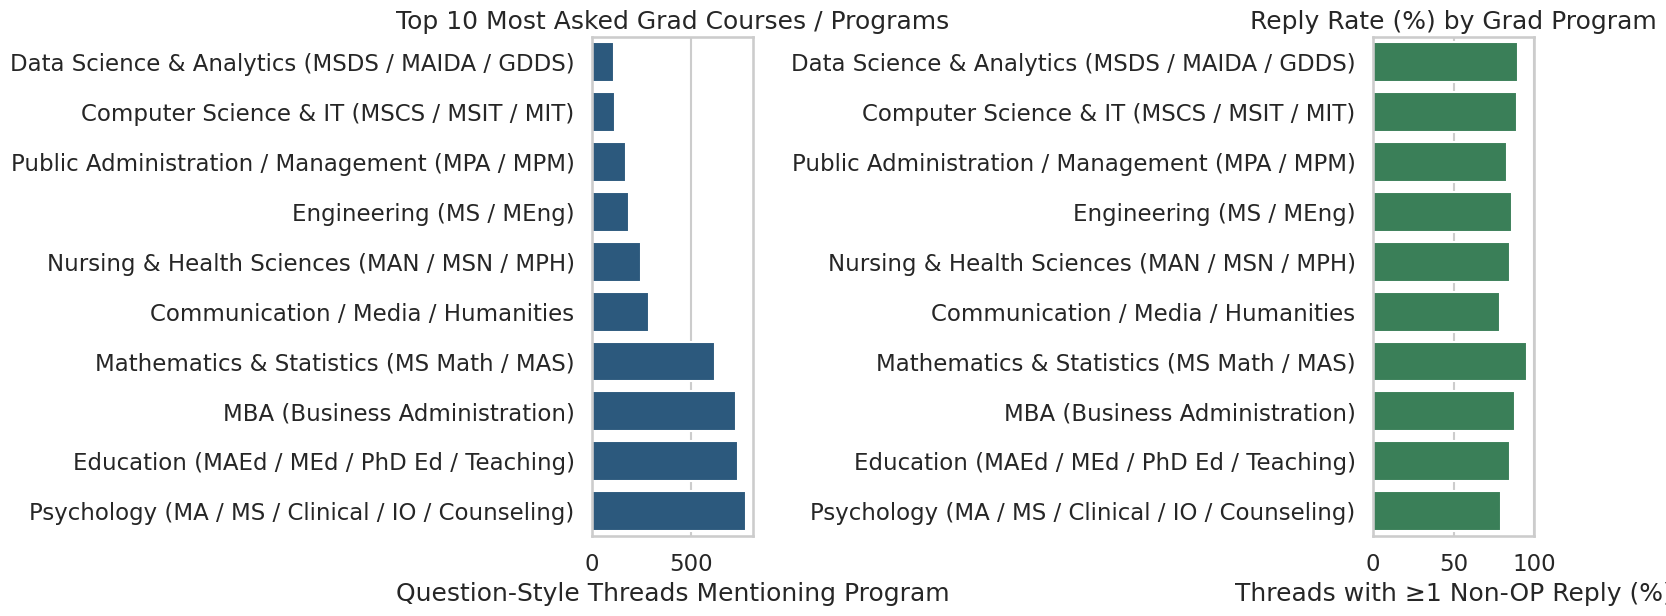

In [95]:
top10 = prog_df.head(10).sort_values("question_threads", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.barplot(
    data=top10,
    x="question_threads",
    y="program_course",
    color="#1F5A8A",
    ax=axes[0],
)
axes[0].set_title("Top 10 Most Asked Grad Courses / Programs")
axes[0].set_xlabel("Question-Style Threads Mentioning Program")
axes[0].set_ylabel("")

sns.barplot(
    data=top10,
    x="reply_rate_pct",
    y="program_course",
    color="#2E8B57",
    ax=axes[1],
)
axes[1].set_title("Reply Rate (%) by Grad Program")
axes[1].set_xlabel("Threads with ≥1 Non-OP Reply (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

In [96]:
for _, row in prog_df.head(10).iterrows():
  prog_name = row["program_course"]
  pat = grad_program_patterns[prog_name]
  matched_q = df_ml[
      full_corpus.str.contains(pat, regex=True) & is_question_post
  ]["title"].dropna()
  print(f"\n### {prog_name} ({row['question_threads']} question threads) ###")
  for t in matched_q.head(3):
    print(f"  - {t}")

/tmp/ipykernel_2673/1709189950.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  full_corpus.str.contains(pat, regex=True) & is_question_post



### Psychology (MA / MS / Clinical / IO / Counseling) (777 question threads) ###
  - Which grad school for MBA?
  - MSc Psych
  - Any thoughts on Master of Science in Psychology?

### Education (MAEd / MEd / PhD Ed / Teaching) (739 question threads) ###
  - r/gradschoolph is here
  - What made you decide to pursue graduate studies?
  - What's next after grad school?

### MBA (Business Administration) (729 question threads) ###
  - r/gradschoolph is here
  - What made you decide to pursue graduate studies?
  - Which grad school for MBA?

### Mathematics & Statistics (MS Math / MAS) (622 question threads) ###
  - Which grad school for MBA?
  - Master's degree students, where do you live?
  - Masters in Statistics - UPD or DLSU?

### Communication / Media / Humanities (288 question threads) ###
  - DLSU Master of Marketing Communications
  - Masters dilemma
  - MA course similar to law

### Nursing & Health Sciences (MAN / MSN / MPH) (250 question threads) ###
  - Is an MA/MS in Psycholo